# Robustness Validation — Multi-Seed Experiment

## Evaluasi Pengaruh Fitur URL-Only dan Validasi Berbasis Domain terhadap Deteksi Phishing Menggunakan Machine Learning

Notebook ini mengevaluasi kestabilan hasil Logistic Regression dan Random Forest pada empat skenario eksperimen menggunakan lima random seed.

Tujuan:
1. Mengukur variasi performa antar pembagian dataset.
2. Membandingkan random split dan domain-grouped split.
3. Mengukur konsistensi pengaruh pembatasan fitur URL-only.
4. Melaporkan rata-rata dan standar deviasi metrik evaluasi.

In [1]:
import pandas as pd
import numpy as np
import json
import time

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    GroupShuffleSplit
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

sns.set_theme(style="whitegrid")

In [2]:
DATA_DIR = Path("../data")
RESULTS_DIR = Path("../results")
FIGURES_DIR = Path("../figures")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    DATA_DIR / "PhiUSIIL_Preprocessed.csv"
)

with open(
    RESULTS_DIR / "feature_config.json",
    "r",
    encoding="utf-8"
) as f:
    config = json.load(f)

full_features = config["full_features"]
url_only_features = config["url_only_features"]

y = df["label"].map({
    0: 1,
    1: 0
})

groups = df["Domain"].astype(str)

print("Jumlah data:", len(df))
print("Full features:", len(full_features))
print("URL-only features:", len(url_only_features))
print("Jumlah domain:", groups.nunique())

Jumlah data: 235370
Full features: 47
URL-only features: 19
Jumlah domain: 220086


In [3]:
assert not y.isna().any()

assert df["URL"].is_unique

assert not groups.isna().any()

assert set(url_only_features).issubset(full_features)

assert np.isfinite(
    df[full_features].to_numpy(dtype=float)
).all()

print("Dataset siap untuk robustness validation.")

Dataset siap untuk robustness validation.


In [4]:
SEEDS = [42, 21, 123, 2026, 7]

TEST_SIZE = 0.30

print("Jumlah seed:", len(SEEDS))
print("Random seeds:", SEEDS)

Jumlah seed: 5
Random seeds: [42, 21, 123, 2026, 7]


In [5]:
def get_models():

    return {
        "Logistic Regression": Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(
                max_iter=1000,
                random_state=42
            ))
        ]),

        "Random Forest": RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )
    }

In [6]:
def create_splits(seed):

    all_idx = np.arange(len(df))

    random_train, random_test = train_test_split(
        all_idx,
        test_size=TEST_SIZE,
        random_state=seed,
        stratify=y
    )

    group_split = GroupShuffleSplit(
        n_splits=1,
        test_size=TEST_SIZE,
        random_state=seed
    )

    grouped_train, grouped_test = next(
        group_split.split(
            df,
            y,
            groups=groups
        )
    )

    train_domains = set(
        groups.iloc[grouped_train]
    )

    test_domains = set(
        groups.iloc[grouped_test]
    )

    overlap = len(
        train_domains.intersection(test_domains)
    )

    assert overlap == 0, \
        "Domain overlap ditemukan."

    return {
        "Random Split": (
            random_train,
            random_test
        ),
        "Domain-Grouped Split": (
            grouped_train,
            grouped_test
        )
    }

In [7]:
SCENARIOS = {
    "A": {
        "features": full_features,
        "split": "Random Split"
    },

    "B": {
        "features": url_only_features,
        "split": "Random Split"
    },

    "C": {
        "features": url_only_features,
        "split": "Domain-Grouped Split"
    },

    "D": {
        "features": full_features,
        "split": "Domain-Grouped Split"
    }
}

In [8]:
def evaluate_robustness(
    model,
    X_train,
    X_test,
    y_train,
    y_test
):

    start_train = time.perf_counter()

    model.fit(X_train, y_train)

    training_time = time.perf_counter() - start_train

    start_inference = time.perf_counter()

    y_pred = model.predict(X_test)

    inference_time = time.perf_counter() - start_inference

    y_prob = model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Training Time (s)": training_time,
        "Inference Time (s)": inference_time,
        "FN": fn,
        "FP": fp
    }

In [9]:
robustness_results = []

for seed in SEEDS:

    print("=" * 60)
    print(f"RANDOM SEED: {seed}")
    print("=" * 60)

    splits = create_splits(seed)

    for scenario, setup in SCENARIOS.items():

        train_idx, test_idx = splits[
            setup["split"]
        ]

        feature_columns = setup["features"]

        X_train = df.iloc[train_idx][feature_columns]
        X_test = df.iloc[test_idx][feature_columns]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        for model_name, model in get_models().items():

            print(
                f"Seed {seed} | "
                f"Scenario {scenario} | "
                f"{model_name}"
            )

            metrics = evaluate_robustness(
                model,
                X_train,
                X_test,
                y_train,
                y_test
            )

            robustness_results.append({
                "Seed": seed,
                "Scenario": scenario,
                "Model": model_name,
                "Feature Type": (
                    "Full Features"
                    if scenario in ["A", "D"]
                    else "URL-Only"
                ),
                "Validation": setup["split"],
                "Training Samples": len(train_idx),
                "Testing Samples": len(test_idx),
                **metrics
            })

            print(
                f"F1: {metrics['F1-Score']:.6f} | "
                f"Recall: {metrics['Recall']:.6f}"
            )

            print("-" * 40)

RANDOM SEED: 42
Seed 42 | Scenario A | Logistic Regression
F1: 0.999154 | Recall: 0.998541
----------------------------------------
Seed 42 | Scenario A | Random Forest
F1: 0.999801 | Recall: 0.999735
----------------------------------------
Seed 42 | Scenario B | Logistic Regression
F1: 0.995439 | Recall: 0.991444
----------------------------------------
Seed 42 | Scenario B | Random Forest
F1: 0.997025 | Recall: 0.994727
----------------------------------------
Seed 42 | Scenario C | Logistic Regression
F1: 0.995637 | Recall: 0.991677
----------------------------------------
Seed 42 | Scenario C | Random Forest
F1: 0.997008 | Recall: 0.995335
----------------------------------------
Seed 42 | Scenario D | Logistic Regression
F1: 0.999093 | Recall: 0.998658
----------------------------------------
Seed 42 | Scenario D | Random Forest
F1: 0.999832 | Recall: 0.999698
----------------------------------------
RANDOM SEED: 21
Seed 21 | Scenario A | Logistic Regression
F1: 0.999104 | Recall

In [10]:
robustness_df = pd.DataFrame(
    robustness_results
)

print(
    "Jumlah eksperimen:",
    len(robustness_df)
)

assert len(robustness_df) == 40

display(
    robustness_df[
        [
            "Seed",
            "Scenario",
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1-Score",
            "ROC-AUC"
        ]
    ].round(6)
)

Jumlah eksperimen: 40


,Seed,Scenario,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,42,A,Logistic Regression,0.999278,0.999768,0.998541,0.999154,0.999964
1,42,A,Random Forest,0.999830,0.999867,0.999735,0.999801,0.999998
2,42,B,Logistic Regression,0.996120,0.999465,0.991444,0.995439,0.998426
3,42,B,Random Forest,0.997465,0.999334,0.994727,0.997025,0.998226
4,42,C,Logistic Regression,0.996312,0.999628,0.991677,0.995637,0.998484
5,42,C,Random Forest,0.997465,0.998687,0.995335,0.997008,0.998490
6,42,D,Logistic Regression,0.999231,0.999530,0.998658,0.999093,0.999980
7,42,D,Random Forest,0.999858,0.999966,0.999698,0.999832,0.999999
8,21,A,Logistic Regression,0.999235,0.999303,0.998906,0.999104,0.999982
9,21,A,Random Forest,0.999873,0.999934,0.999768,0.999851,1.000000


In [11]:
robustness_df.to_csv(
    RESULTS_DIR / "robustness_multiseed_metrics.csv",
    index=False
)

print("Hasil multi-seed berhasil disimpan.")

Hasil multi-seed berhasil disimpan.


In [12]:
metrics_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

robustness_summary = (
    robustness_df
    .groupby(["Scenario", "Model"])[metrics_columns]
    .agg(["mean", "std"])
    .reset_index()
)

robustness_summary.columns = [
    "_".join(col).strip("_")
    for col in robustness_summary.columns
]

display(robustness_summary.round(6))

,Scenario,Model,Accuracy_mean,Accuracy_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1-Score_mean,F1-Score_std,ROC-AUC_mean,ROC-AUC_std
0,A,Logistic Regression,0.999176,0.000140,0.999442,0.000221,0.998627,0.000245,0.999035,0.000164,0.999983,0.000012
1,A,Random Forest,0.999867,0.000021,0.999927,0.000049,0.999761,0.000028,0.999844,0.000025,0.999996,0.000008
2,B,Logistic Regression,0.996227,0.000146,0.999552,0.000102,0.991610,0.000299,0.995565,0.000172,0.998377,0.000108
3,B,Random Forest,0.997439,0.000171,0.998955,0.000225,0.995046,0.000470,0.996996,0.000201,0.998431,0.000151
4,C,Logistic Regression,0.996244,0.000303,0.999565,0.000139,0.991563,0.000672,0.995548,0.000401,0.998336,0.000169
5,C,Random Forest,0.997457,0.000022,0.998906,0.000158,0.995089,0.000208,0.996994,0.000040,0.998454,0.000036
6,D,Logistic Regression,0.999283,0.000148,0.999473,0.000151,0.998834,0.000271,0.999153,0.000181,0.999981,0.000009
7,D,Random Forest,0.999866,0.000022,0.999953,0.000052,0.999732,0.000070,0.999842,0.000025,0.999999,0.000001


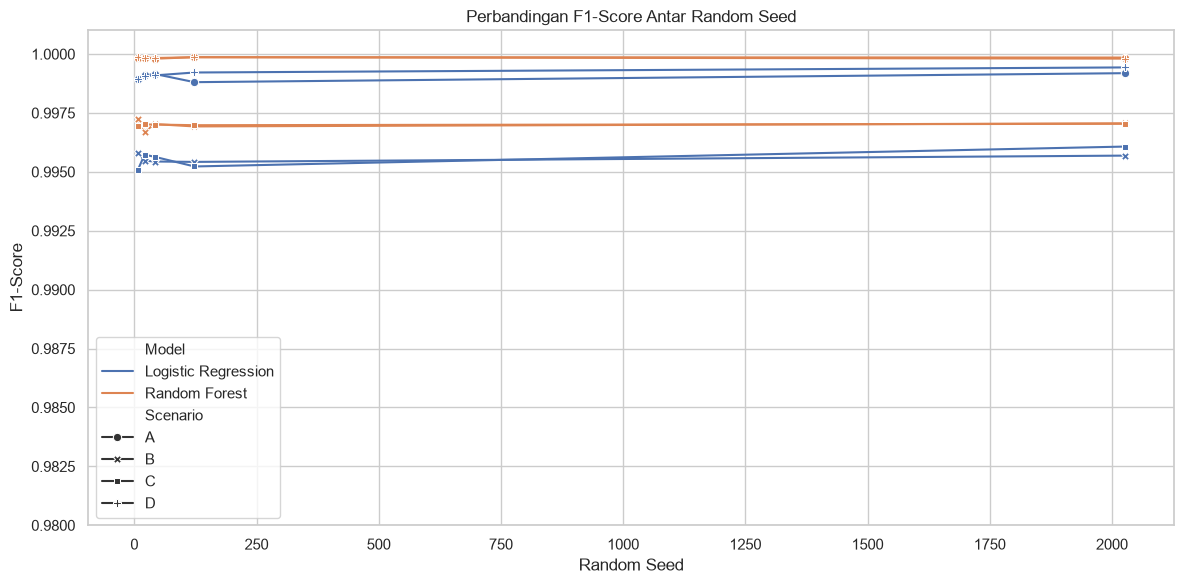

In [13]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=robustness_df,
    x="Seed",
    y="F1-Score",
    hue="Model",
    style="Scenario",
    markers=True,
    dashes=False,
    estimator=None
)

plt.title("Perbandingan F1-Score Antar Random Seed")
plt.xlabel("Random Seed")
plt.ylabel("F1-Score")

plt.ylim(0.98, 1.001)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "robustness_f1_by_seed.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

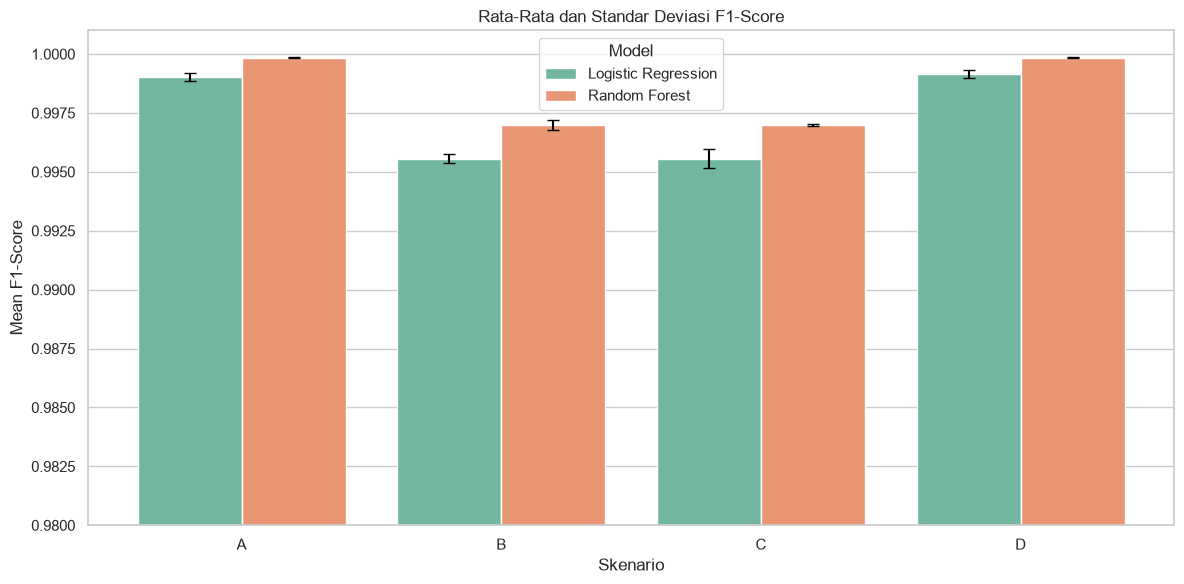

In [14]:
summary_plot = (
    robustness_df
    .groupby(["Scenario", "Model"])["F1-Score"]
    .agg(["mean", "std"])
    .reset_index()
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=summary_plot,
    x="Scenario",
    y="mean",
    hue="Model",
    palette="Set2",
    errorbar=None
)

model_order = list(summary_plot["Model"].unique())
scenario_order = list(summary_plot["Scenario"].unique())

for container, model_name in zip(
    ax.containers,
    model_order
):
    subset = (
        summary_plot[
            summary_plot["Model"] == model_name
        ]
        .set_index("Scenario")
        .loc[scenario_order]
    )

    positions = [
        patch.get_x() + patch.get_width() / 2
        for patch in container
    ]

    plt.errorbar(
        positions,
        subset["mean"],
        yerr=subset["std"],
        fmt="none",
        capsize=4,
        color="black"
    )

plt.title("Rata-Rata dan Standar Deviasi F1-Score")
plt.xlabel("Skenario")
plt.ylabel("Mean F1-Score")

plt.ylim(0.98, 1.001)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "robustness_f1_mean_std.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
pivot_f1 = robustness_df.pivot_table(
    index=["Seed", "Model"],
    columns="Scenario",
    values="F1-Score"
)

comparison_multiseed = pd.DataFrame({
    "Feature Effect Random (pp)": (
        pivot_f1["B"] - pivot_f1["A"]
    ) * 100,

    "Feature Effect Grouped (pp)": (
        pivot_f1["C"] - pivot_f1["D"]
    ) * 100,

    "Split Effect Full (pp)": (
        pivot_f1["D"] - pivot_f1["A"]
    ) * 100,

    "Split Effect URL-Only (pp)": (
        pivot_f1["C"] - pivot_f1["B"]
    ) * 100
}).reset_index()

display(
    comparison_multiseed.round(6)
)

,Seed,Model,Feature Effect Random (pp),Feature Effect Grouped (pp),Split Effect Full (pp),Split Effect URL-Only (pp)
0,7,Logistic Regression,-0.311592,-0.388368,0.003496,-0.073280
1,7,Random Forest,-0.259076,-0.292941,0.001248,-0.032617
2,21,Logistic Regression,-0.363313,-0.333912,-0.003704,0.025697
3,21,Random Forest,-0.314100,-0.283636,-0.000333,0.030131
4,42,Logistic Regression,-0.371522,-0.345690,-0.006041,0.019792
5,42,Random Forest,-0.277578,-0.282407,0.003115,-0.001714
6,123,Logistic Regression,-0.338349,-0.398817,0.041083,-0.019384
7,123,Random Forest,-0.294038,-0.288416,-0.000361,0.005261
8,2026,Logistic Regression,-0.349867,-0.335907,0.024425,0.038384
9,2026,Random Forest,-0.279102,-0.276629,-0.004566,-0.002093


In [16]:
effect_columns = [
    "Feature Effect Random (pp)",
    "Feature Effect Grouped (pp)",
    "Split Effect Full (pp)",
    "Split Effect URL-Only (pp)"
]

effect_summary = (
    comparison_multiseed
    .groupby("Model")[effect_columns]
    .agg(["mean", "std"])
)

display(
    effect_summary.round(6)
)

Feature Effect Random (pp)            \
                                          mean       std   
Model                                                      
Logistic Regression                  -0.346929  0.023475   
Random Forest                        -0.284779  0.020556   

                    Feature Effect Grouped (pp)            \
                                           mean       std   
Model                                                       
Logistic Regression                   -0.360539  0.030724   
Random Forest                         -0.284806  0.006189   

                    Split Effect Full (pp)            \
                                      mean       std   
Model                                                  
Logistic Regression               0.011852  0.020276   
Random Forest                    -0.000179  0.002837   

                    Split Effect URL-Only (pp)            
                                          mean       std  
Model                                                     
Logistic Regression                  -0.001758  0.045430  
Random Forest                        -0.000206  0.022397

In [17]:
robustness_summary.to_csv(
    RESULTS_DIR / "robustness_summary.csv",
    index=False
)

comparison_multiseed.to_csv(
    RESULTS_DIR / "robustness_effect_comparison.csv",
    index=False
)

effect_summary.to_csv(
    RESULTS_DIR / "robustness_effect_summary.csv"
)

print("Seluruh hasil robustness validation berhasil disimpan.")

Seluruh hasil robustness validation berhasil disimpan.


Pengujian kestabilan dilakukan menggunakan lima random seed, yaitu 42, 21, 123, 2026, dan 7, dengan total 40 eksperimen yang melibatkan Logistic Regression dan Random Forest pada empat skenario pembagian fitur dan strategi validasi. Hasil menunjukkan bahwa Random Forest memperoleh rata-rata F1-score lebih tinggi dibandingkan Logistic Regression pada seluruh skenario. Pembatasan fitur menjadi URL-only menyebabkan penurunan rata-rata F1-score sebesar 0,2848–0,3605 poin persentase dibandingkan penggunaan full features.

Sementara itu, perubahan strategi pembagian data dari random split menjadi domain-grouped split menghasilkan perbedaan rata-rata F1-score yang relatif kecil, yaitu antara −0,0018 hingga +0,0119 poin persentase. Hasil ini menunjukkan bahwa dugaan penurunan performa yang besar akibat pemisahan domain belum memperoleh dukungan dari eksperimen yang dilakukan. Standar deviasi F1-score yang relatif kecil juga menunjukkan konsistensi performa pada lima pembagian data yang diuji. Namun, penelitian ini masih terbatas pada satu dataset dan belum membuktikan kesetaraan kedua strategi validasi secara statistik.